In [3]:
# PART 1 

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.mixture import GaussianMixture
!pip install seaborn
import seaborn as sns
from PIL import Image
import os

In [5]:
rng = np.random.default_rng(42)

K = 5
N = 2000

weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])

means_0 = np.array([
    [-4.0, -3.0],
    [-2.0,  2.0],
    [ 0.0, -1.0],
    [ 2.0,  3.0],
    [ 4.0, -2.0]
])

means_1 = np.array([
    [-4.0,  3.0],
    [-2.0, -2.0],
    [ 0.0,  4.0],
    [ 2.0, -3.0],
    [ 4.0,  2.0]
])

covariance_types = {
    "Isotropic": [
        1.0 * np.eye(2),
        0.8 * np.eye(2),
        1.2 * np.eye(2),
        0.6 * np.eye(2),
        1.5 * np.eye(2)
    ],

    "Diagonal": [
        np.array([[1.5, 0.0],
                  [0.0, 0.4]]),

        np.array([[0.5, 0.0],
                  [0.0, 1.5]]),

        np.array([[1.2, 0.0],
                  [0.0, 0.6]]),

        np.array([[0.8, 0.0],
                  [0.0, 1.8]]),

        np.array([[2.0, 0.0],
                  [0.0, 0.7]])
    ],

    "Full": [
        np.array([[1.5, 0.8],
                  [0.8, 1.0]]),

        np.array([[1.2, -0.6],
                  [-0.6, 1.0]]),

        np.array([[0.8, 0.3],
                  [0.3, 1.4]]),

        np.array([[1.5, -0.5],
                  [-0.5, 0.8]]),

        np.array([[1.0, 0.6],
                  [0.6, 1.5]])
    ]
}

In [6]:
def gaussian_density(x, mean, covariance):
    d = len(mean)
    diff = x - mean

    det = np.linalg.det(covariance)
    inv = np.linalg.inv(covariance)

    exponent = -0.5 * diff.T @ inv @ diff

    coefficient = 1 / (
        (2 * np.pi) ** (d / 2) * np.sqrt(det)
    )

    return coefficient * np.exp(exponent)



def box_muller(n_samples, rng):
    u1 = rng.random(n_samples)
    u2 = rng.random(n_samples)

    u1 = np.maximum(u1, np.finfo(float).tiny)

    r = np.sqrt(-2.0 * np.log(u1))
    theta = 2.0 * np.pi * u2

    z1 = r * np.cos(theta)
    z2 = r * np.sin(theta)

    return np.column_stack((z1, z2))


def generate_gmm_data(means, covariances, n_samples):
    component_ids = rng.choice(
        K, size=n_samples, p=weights
    )

    X = np.zeros((n_samples, len(means[0])))

    for i in range(K):
        indices = np.where(component_ids == i)[0]
        n_component = len(indices)

        if n_component == 0:
            continue

        Z = box_muller(n_component, rng)

        L = np.linalg.cholesky(covariances[i])

        X[indices] = means[i] + Z @ L.T

    return X, component_ids


Covariance type: Isotropic
Accuracy: 82.00%
Confusion matrix:
 [[330  70]
 [ 74 326]]
              precision    recall  f1-score   support

           0       0.82      0.82      0.82       400
           1       0.82      0.81      0.82       400

    accuracy                           0.82       800
   macro avg       0.82      0.82      0.82       800
weighted avg       0.82      0.82      0.82       800



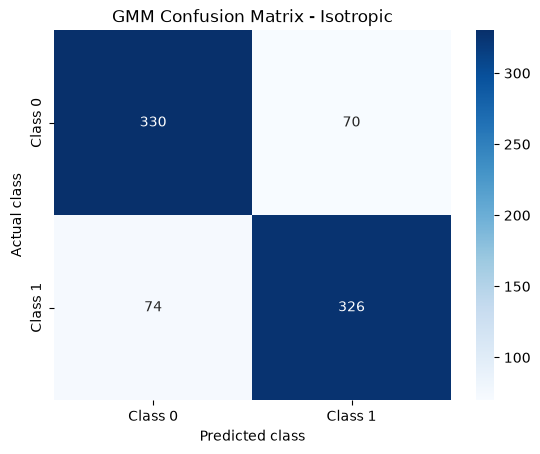


Covariance type: Diagonal
Accuracy: 80.38%
Confusion matrix:
 [[337  63]
 [ 94 306]]
              precision    recall  f1-score   support

           0       0.78      0.84      0.81       400
           1       0.83      0.77      0.80       400

    accuracy                           0.80       800
   macro avg       0.81      0.80      0.80       800
weighted avg       0.81      0.80      0.80       800



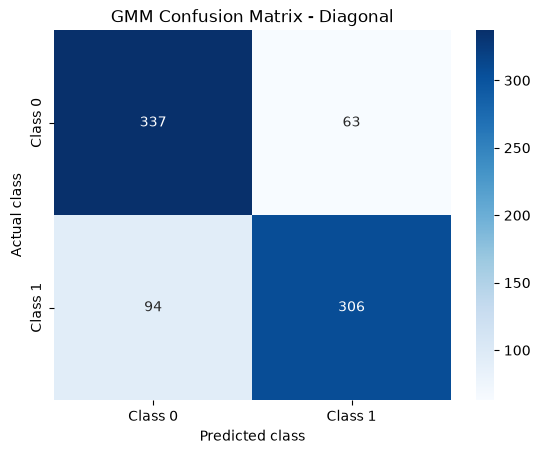


Covariance type: Full
Accuracy: 81.75%
Confusion matrix:
 [[310  90]
 [ 56 344]]
              precision    recall  f1-score   support

           0       0.85      0.78      0.81       400
           1       0.79      0.86      0.82       400

    accuracy                           0.82       800
   macro avg       0.82      0.82      0.82       800
weighted avg       0.82      0.82      0.82       800



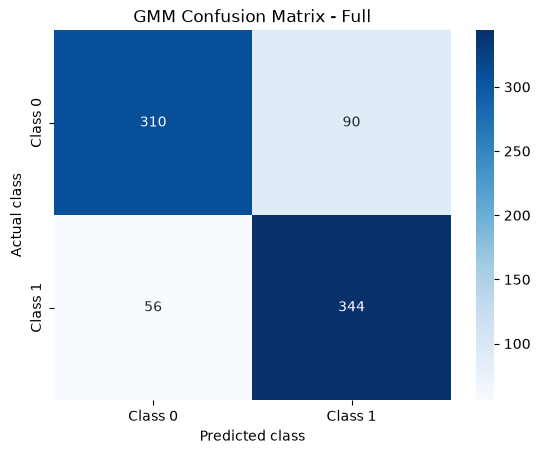

In [7]:
for covariance_name, covariances in covariance_types.items():

    print(f"\n{'=' * 45}")
    print("Covariance type:", covariance_name)

    X0, _ = generate_gmm_data(means_0, covariances, N)
    X1, _ = generate_gmm_data(means_1, covariances, N)

    X = np.vstack([X0, X1])
    y = np.concatenate([
        np.zeros(N, dtype=int),
        np.ones(N, dtype=int)
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    models = {}

    for class_label in [0, 1]:
        class_data = X_train[y_train == class_label]

        gmm = GaussianMixture(
            n_components=K,
            covariance_type="full",
            reg_covar=1e-5,
            max_iter=200,
            n_init=3,
            random_state=42
        )

        gmm.fit(class_data)
        models[class_label] = gmm

    scores = np.column_stack([
        models[0].score_samples(X_test),
        models[1].score_samples(X_test)
    ])

    y_pred = np.argmax(scores, axis=1)

    print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    print("Confusion matrix:\n", cm)

    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        zero_division=0
    ))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Class 0", "Class 1"],
        yticklabels=["Class 0", "Class 1"]
    )

    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.title(f"GMM Confusion Matrix - {covariance_name}")
    plt.show()

In [8]:
# PART 2

In [13]:
DATA_DIR = r"D:\M_tech_first_sem\PRML\Lab_7\dataset"

In [14]:
DIGITS = [4, 5, 9]

def load_images(split):
    X, y, paths = [], [], []

    for digit in DIGITS:
        folder = os.path.join(DATA_DIR, split, str(digit))

        for filename in os.listdir(folder):
            filepath = os.path.join(folder, filename)

            try:
                with Image.open(filepath) as img:
                    img = img.convert("L").resize((28, 28))

                    pixels = np.asarray(
                        img, dtype=np.float32
                    ) / 255.0

                    X.append(pixels.flatten())
                    y.append(digit)
                    paths.append(filepath)

            except (OSError, ValueError):
                continue

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=int),
        paths
    )

X_train, y_train, train_paths = load_images("train")
X_dev, y_dev, dev_paths = load_images("dev")
X_test, y_test, test_paths = load_images("test")

print("Train:", X_train.shape, y_train.shape)
print("Dev:", X_dev.shape, y_dev.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (13825, 784) (13825,)
Dev: (3387, 784) (3387,)
Test: (2883, 784) (2883,)


In [15]:

K_VALUES = [1, 3, 5, 8]
RANDOM_STATE = 42


def train_gmms(X, y, K):
    models = {}

    for digit in DIGITS:
        digit_data = X[y == digit]

        model = GaussianMixture(
            n_components=K,
            covariance_type="diag",
            reg_covar=1e-5,
            max_iter=200,
            n_init=1,
            random_state=RANDOM_STATE
        )

        model.fit(digit_data)
        models[digit] = model

    return models


def get_log_likelihoods(models, X):
    return np.column_stack([
        models[digit].score_samples(X)
        for digit in DIGITS
    ])


def predict_from_scores(scores):
    return np.asarray(DIGITS)[np.argmax(scores, axis=1)]


# Tune K using dev data
best_K = None
best_dev_accuracy = -1
best_models = None

for K in K_VALUES:
    print(f"\nTraining candidate GMMs with K={K}")

    models = train_gmms(X_train, y_train, K)

    dev_scores = get_log_likelihoods(models, X_dev)
    dev_predictions = predict_from_scores(dev_scores)

    dev_accuracy = accuracy_score(
        y_dev, dev_predictions
    )

    print(f"Development accuracy: {dev_accuracy:.4f}")

    for digit in DIGITS:
        print(
            f"Digit {digit}: converged =",
            models[digit].converged_,
            "| iterations =", models[digit].n_iter_
        )

    if dev_accuracy > best_dev_accuracy:
        best_dev_accuracy = dev_accuracy
        best_K = K
        best_models = models

print("\nSelected K:", best_K)
print("Best development accuracy:", best_dev_accuracy)

for digit, model in best_models.items():
    print(f"\nGMM for digit {digit}")
    print("Mixture weights:", model.weights_)
    print("Means shape:", model.means_.shape)
    print("Variances shape:", model.covariances_.shape)



Training candidate GMMs with K=1
Development accuracy: 0.7727
Digit 4: converged = True | iterations = 2
Digit 5: converged = True | iterations = 2
Digit 9: converged = True | iterations = 2

Training candidate GMMs with K=3
Development accuracy: 0.8329
Digit 4: converged = True | iterations = 26
Digit 5: converged = True | iterations = 20
Digit 9: converged = True | iterations = 11

Training candidate GMMs with K=5
Development accuracy: 0.8465
Digit 4: converged = True | iterations = 19
Digit 5: converged = True | iterations = 24
Digit 9: converged = True | iterations = 18

Training candidate GMMs with K=8
Development accuracy: 0.8866
Digit 4: converged = True | iterations = 21
Digit 5: converged = True | iterations = 26
Digit 9: converged = True | iterations = 21

Selected K: 8
Best development accuracy: 0.8866253321523472

GMM for digit 4
Mixture weights: [0.09762224 0.06685054 0.32215023 0.10878042 0.0862645  0.14537497
 0.11356813 0.05938902]
Means shape: (8, 784)
Variances shape

Test accuracy: 89.80%

Classification report:
              precision    recall  f1-score   support

           4     0.9286    0.8075    0.8638       982
           5     0.9440    0.9641    0.9540       892
           9     0.8372    0.9277    0.8801      1009

    accuracy                         0.8980      2883
   macro avg     0.9033    0.8998    0.8993      2883
weighted avg     0.9014    0.8980    0.8974      2883

Confusion matrix:
[[793  25 164]
 [ 14 860  18]
 [ 47  26 936]]


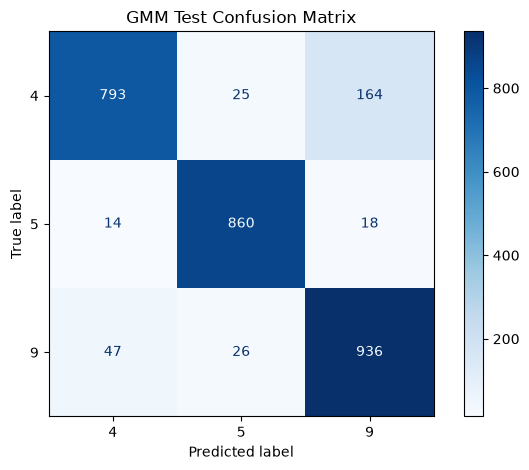

In [18]:

test_scores = get_log_likelihoods(best_models, X_test)
y_pred = predict_from_scores(test_scores)

test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=DIGITS,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(y_test, y_pred, labels=DIGITS)

print("Confusion matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=DIGITS
)

disp.plot(cmap="Blues", values_format="d")
plt.title("GMM Test Confusion Matrix")
plt.tight_layout()
plt.show()


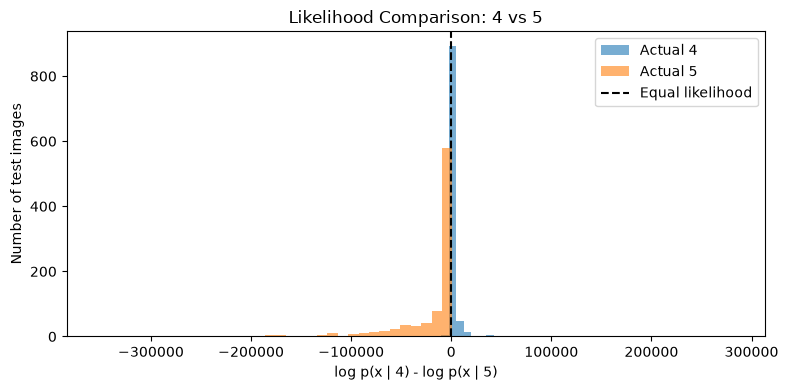

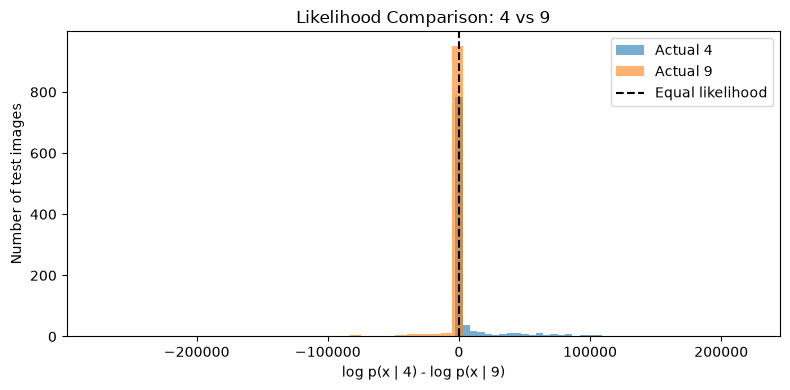

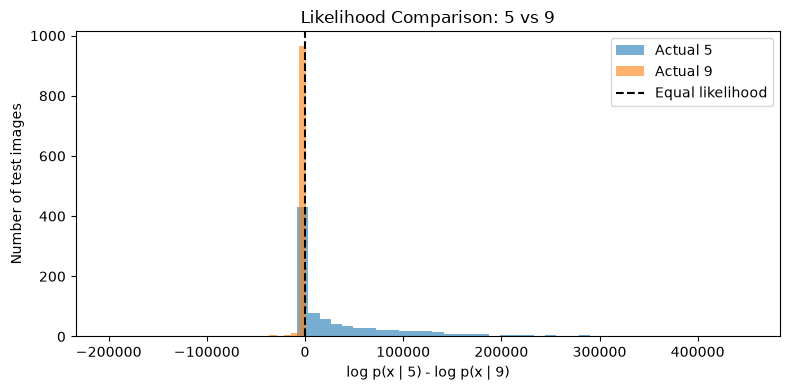

In [19]:

# Plot likelihood differences for each pair of digits
for i in range(len(DIGITS)):
    for j in range(i + 1, len(DIGITS)):
        a = DIGITS[i]
        b = DIGITS[j]

        # Positive: model a scores higher
        # Negative: model b scores higher
        differences = test_scores[:, i] - test_scores[:, j]

        # Select only images belonging to digits a or b
        relevant = (y_test == a) | (y_test == b)

        # Apply the mask to BOTH arrays
        relevant_differences = differences[relevant]
        relevant_labels = y_test[relevant]

        plt.figure(figsize=(8, 4))

        plt.hist(
            relevant_differences[relevant_labels == a],
            bins=40,
            alpha=0.6,
            label=f"Actual {a}"
        )

        plt.hist(
            relevant_differences[relevant_labels == b],
            bins=40,
            alpha=0.6,
            label=f"Actual {b}"
        )

        plt.axvline(
            0, linestyle="--", color="black",
            label="Equal likelihood"
        )

        plt.xlabel(f"log p(x | {a}) - log p(x | {b})")
        plt.ylabel("Number of test images")
        plt.title(f"Likelihood Comparison: {a} vs {b}")
        plt.legend()
        plt.tight_layout()
        plt.show()


In [ ]:
# PLOTS

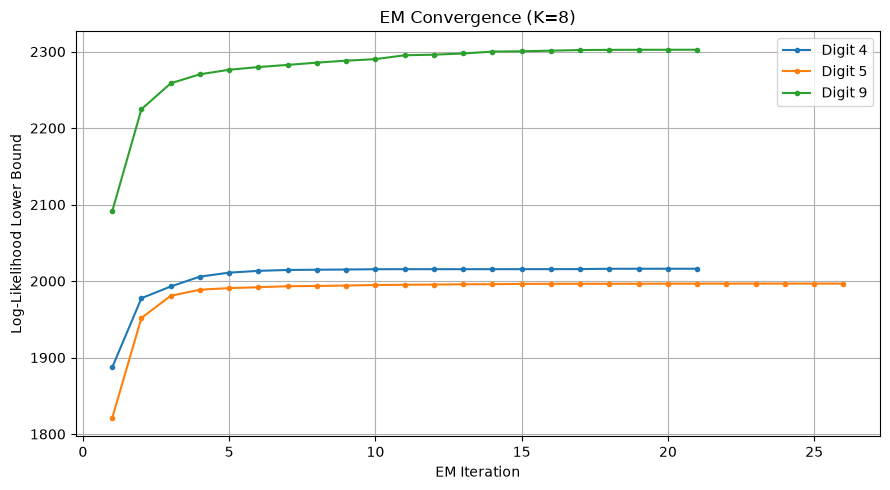

In [25]:

def plot_em_convergence(models):
    plt.figure(figsize=(9, 5))

    for digit, model in models.items():
        iterations = range(1, len(model.lower_bounds_) + 1)

        plt.plot(
            iterations,
            model.lower_bounds_,
            marker="o",
            markersize=3,
            label=f"Digit {digit}"
        )

    plt.xlabel("EM Iteration")
    plt.ylabel("Log-Likelihood Lower Bound")
    plt.title(f"EM Convergence (K={best_K})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


plot_em_convergence(best_models)
